In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import sqlite3
from scipy.stats import ttest_ind
import scipy.stats as stats
warnings.filterwarnings('ignore')

In [7]:
# creating database connection
conn = sqlite3.connect('inventory.db')

# fetching vendor summary data
df = pd.read_sql_query("select * from vendor_sales_summary",conn)
df.head()

,VendorNumber,VendorName,Brand,Description,PurchasePrice,ActualPrice,Volume,TotalPurchaseQuantity,TotalPurchaseDollars,TotalSalesQuantity,TotalSalesDollars,TotalSalesPrice,TotalExciseTax,FreightCost,GrossProfit,ProfitMargin,StockTurnover,SalestoPurchaseRatio
0,1128,BROWN-FORMAN CORP,1233,Jack Daniels No 7 Black,26.27,36.99,1750.0,145080,3811251.60,142049.0,5101919.51,672819.31,260999.20,68601.68,1290667.91,25.297693,0.979108,1.338647
1,4425,MARTIGNETTI COMPANIES,3405,Tito's Handmade Vodka,23.19,28.99,1750.0,164038,3804041.22,160247.0,4819073.49,561512.37,294438.66,144929.24,1015032.27,21.062810,0.976890,1.266830
2,17035,PERNOD RICARD USA,8068,Absolut 80 Proof,18.24,24.99,1750.0,187407,3418303.68,187140.0,4538120.60,461140.15,343854.07,123780.22,1119816.92,24.675786,0.998575,1.327594
3,3960,DIAGEO NORTH AMERICA INC,4261,Capt Morgan Spiced Rum,16.17,22.99,1750.0,201682,3261197.94,200412.0,4475972.88,420050.01,368242.80,257032.07,1214774.94,27.139908,0.993703,1.372493
4,3960,DIAGEO NORTH AMERICA INC,3545,Ketel One Vodka,21.89,29.99,1750.0,138109,3023206.01,135838.0,4223107.62,545778.28,249587.83,257032.07,1199901.61,28.412764,0.983556,1.396897


Exploratory Data Analysis
    
Previously, we examined the various tables in the database to identify key variables, understand their relationships, and determine which ones   should be included in the final analysis.
    
In this phase of EDA, we will analyze the resultant table to gain insights into the distribution of each column. This will help us understand data patterns, identify anomalies, and ensure data quality before proceeding with further analysis.

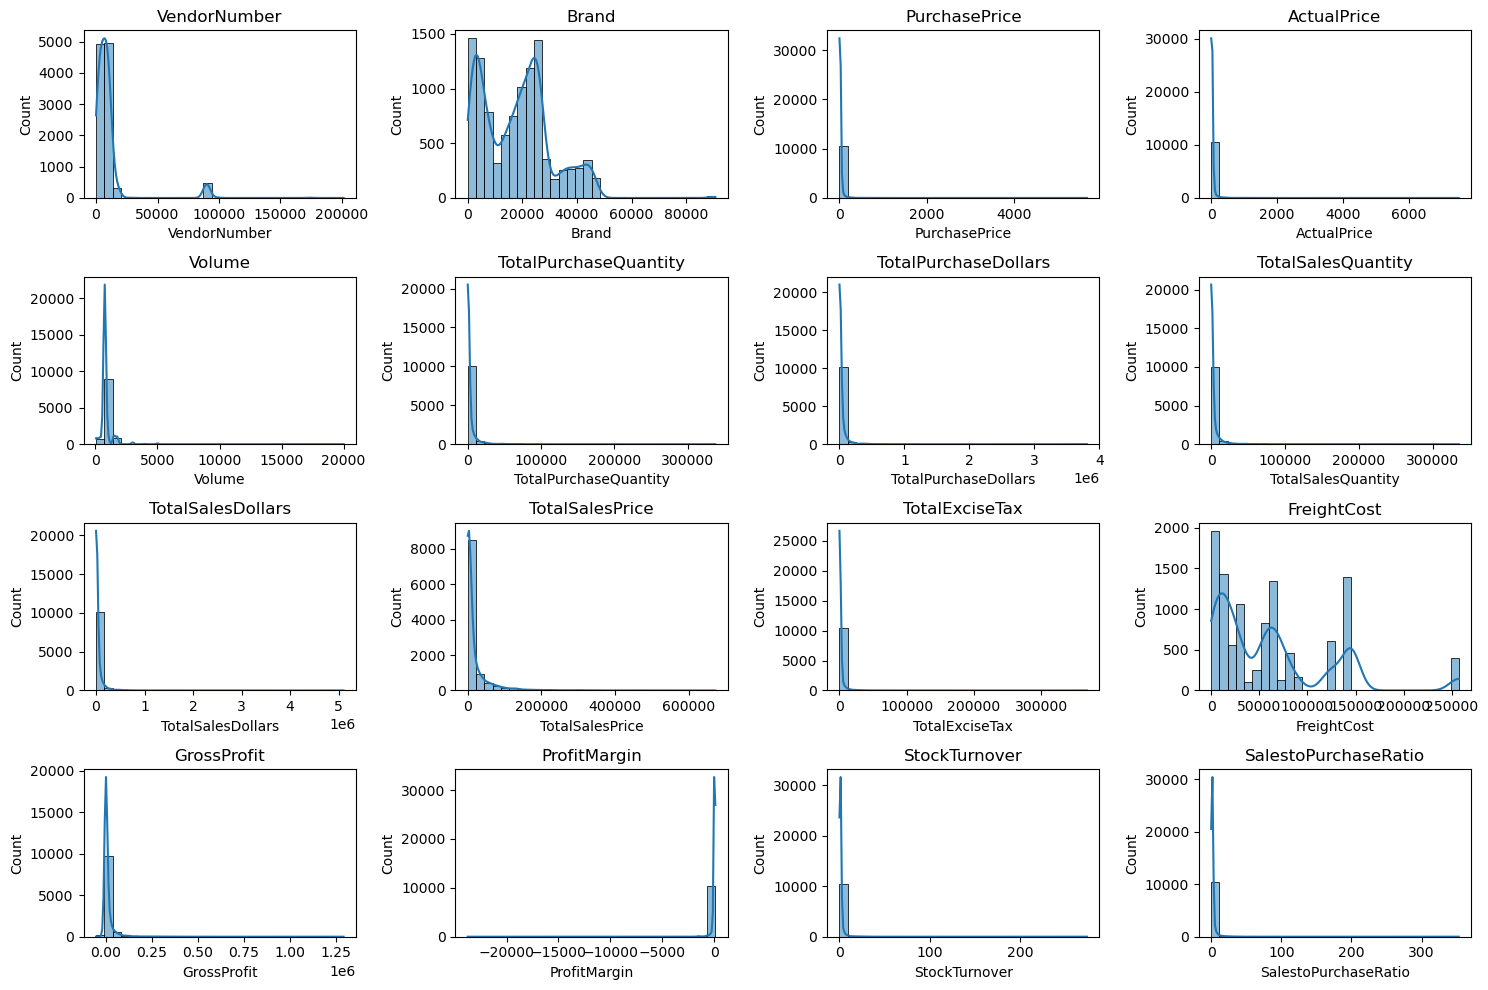

In [8]:
#Distribution Plots for Numerical Columns
numerical_cols = df.select_dtypes(include=np.number).columns
plt.figure(figsize=(15, 10))
for i, col in enumerate(numerical_cols):
    plt.subplot(4, 4, i+1) # Adjust grid layout as needed
    sns.histplot(df [col], kde=True, bins=30)
    plt.title(col)
plt.tight_layout()
plt.show()

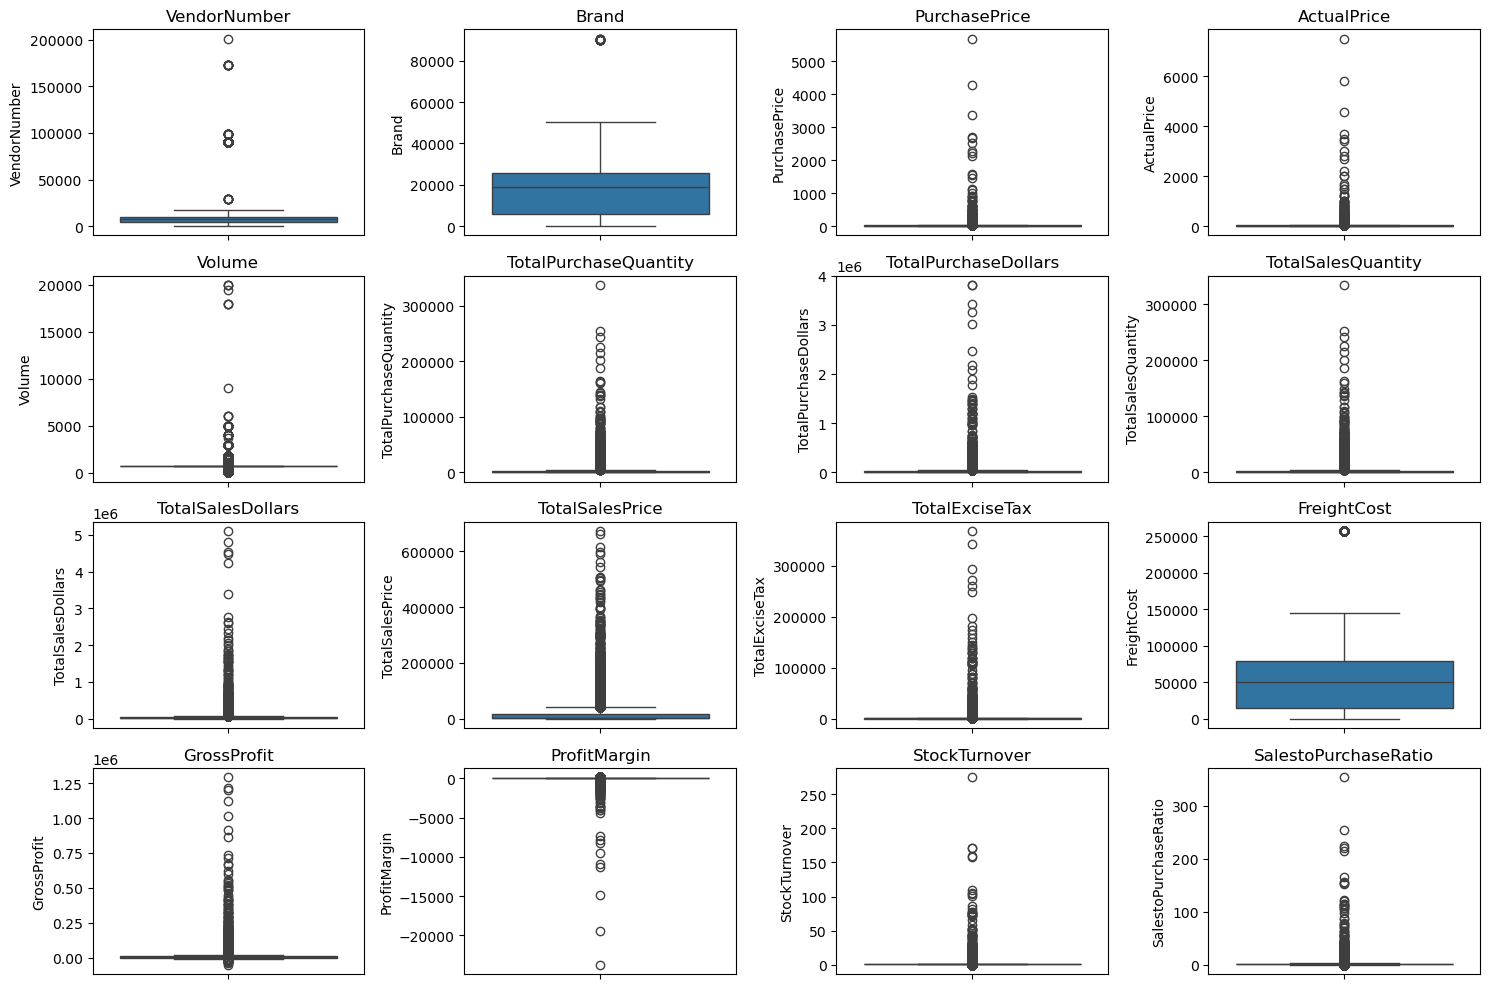

In [9]:
# Outlier Detection with Boxplots
plt.figure(figsize=(15, 10))
for i, col in enumerate(numerical_cols):
    plt.subplot(4, 4, i+1)
    sns.boxplot(y=df[col])
    plt.title(col)
plt.tight_layout()
plt.show()

Summary Statistics insights.

Negative & Zero Values:

Gross Profit: Minimum value is -52,002.78, indicating losses. Some products or transactions may be selling at a loss due to high costs or selling at discounts lower than the purchase price..
Profit Margin: Has a minimum of -∞, which suggests cases where revenue is zero or even lower than costs.
Total Sales Quantity & Sales Dollars: Minimum values are 0, meaning some products were purchased but never sold. These could be slow-moving or absolete stock.

Outliers Indicated by High Standard Deviations:

Purchase & Actual Prices: The max values (5,681.81 & 7,499.99) are significantly higher than the mean (24.39 & 35.64), indicating potential premium products.

Freight Cost: Huge variation, from 0.09 to 257,032.07, suggests logistics inefficiencies or bulk shipments.

Stock Turnover: Ranges from 0 to 274.5, implying some products sell extremely fast while others remain in stock indefinitely. Value more than 1 indicates that Sold quantity for that product is higher than purchased quantity due to either sales are being fulfilled from older stock.

In [11]:
# let's filter the data by removing inconsistencies

df = pd.read_sql_query("""SELECT *
FROM vendor_sales_summary
WHERE GrossProfit > 0
AND ProfitMargin > 0
AND TotalSalesQuantity > 0""", conn)

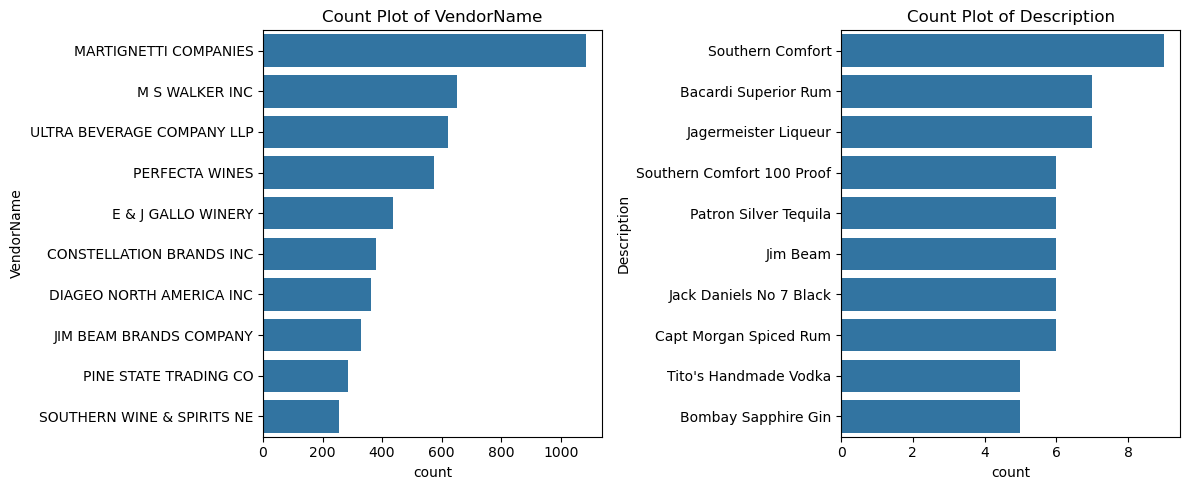

In [21]:
#Count Plots for Categorical Columns
categorical_cols = ["VendorName", "Description"]
plt.figure(figsize=(12,5))
for i, col in enumerate (categorical_cols):
    plt.subplot(1, 2, i+1)
    sns.countplot(y=df[col], order=df[col].value_counts().index[:10]) # Top 10 categories
    plt.title(f"Count Plot of {col}")
plt.tight_layout()
plt.show()

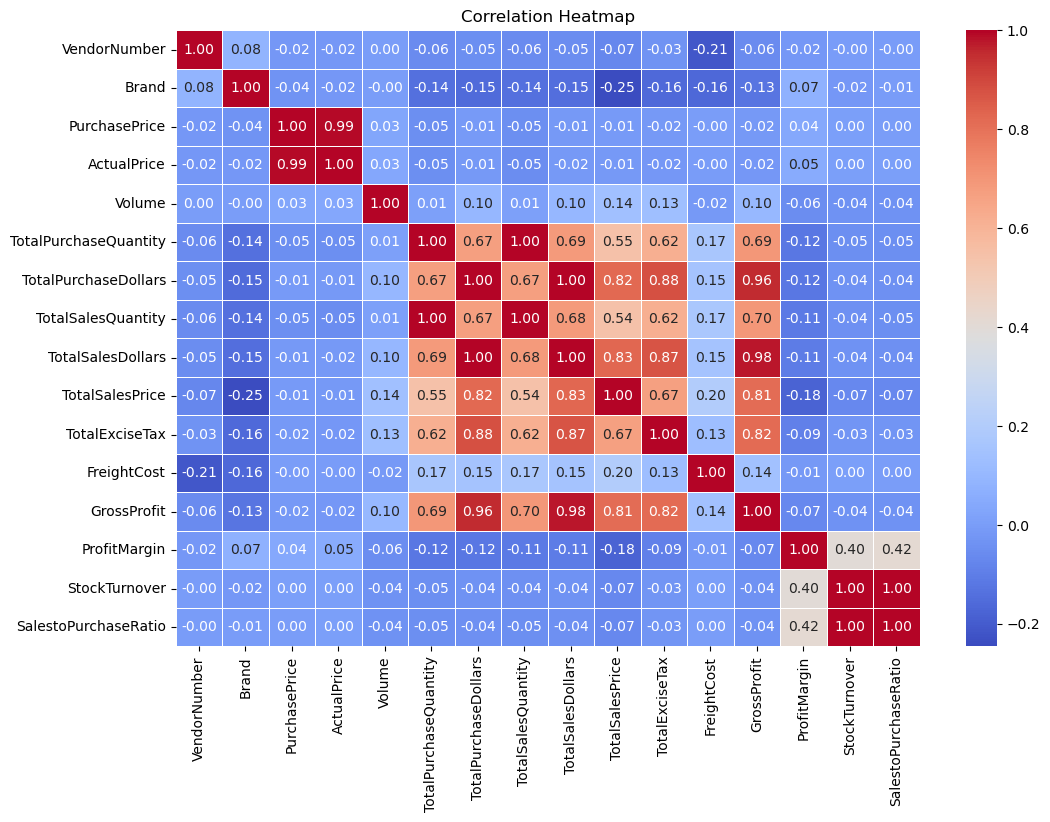

In [23]:
# Correlation Heatmap
plt.figure(figsize=(12, 8))
correlation_matrix = df [numerical_cols].corr()
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.5)
plt.title("Correlation Heatmap")
plt.show()

Correlation Insights

Purchase Price has weak correlations with TotalSales Dollars (-0.012) and GrossProfit (-0.016), suggesting that price variations do not significantly impact sales revenue or profit.

Strong correlation between total purchase quantity and total sales quantity (0.999), confirming efficient inventory turnover

Negative correlation between profit margin & total sales price (-0.179) suggests that as sales price increases, margins decrease, possibly due to competitive pricing pressures.

Stock Turnover has weak negative correlations with both GrossProfit (-0.038) and ProfitMargin (-0.055), indicating that faster turnover does not necessarily result in higher profitability.


Data Analysis

Identify Brands that needs Promotional or Pricing Adjustments which exhibit lower sales performance but higher profit margins.


In [24]:
brand_performance = df.groupby('Description').agg({
    'TotalSalesDollars': 'sum',
    'ProfitMargin': 'mean'}).reset_index()

In [25]:
low_sales_threshold = brand_performance ['TotalSalesDollars'].quantile(0.15)
high_margin_threshold = brand_performance ['ProfitMargin'].quantile(0.85)

In [26]:
low_sales_threshold


np.float64(560.357)

In [27]:
high_margin_threshold

np.float64(65.03587868318036)

In [30]:
# Filter brands with low sales but high profit margins
target_brands = brand_performance[
    (brand_performance ['TotalSalesDollars'] <= low_sales_threshold) & 
    (brand_performance ['ProfitMargin'] >= high_margin_threshold)]
print("Brands with Low Sales but High Profit Margins:")
display(target_brands.sort_values('TotalSalesDollars'))

Brands with Low Sales but High Profit Margins:


,Description,TotalSalesDollars,ProfitMargin
6199,Santa Rita Organic Svgn Bl,9.99,66.466466
2369,Debauchery Pnt Nr,11.58,65.975820
2070,Concannon Glen Ellen Wh Zin,15.95,83.448276
2188,Crown Royal Apple,27.86,89.806174
6237,Sauza Sprklg Wild Berry Marg,27.96,82.153076
...,...,...,...
5074,Nanbu Bijin Southern Beauty,535.68,76.747312
2271,Dad's Hat Rye Whiskey,538.89,81.851584
57,A Bichot Clos Marechaudes,539.94,67.740860
6245,Sbragia Home Ranch Merlot,549.75,66.444748


In [31]:
brand_performance = brand_performance[brand_performance['TotalSalesDollars']<10000] #for better visualization

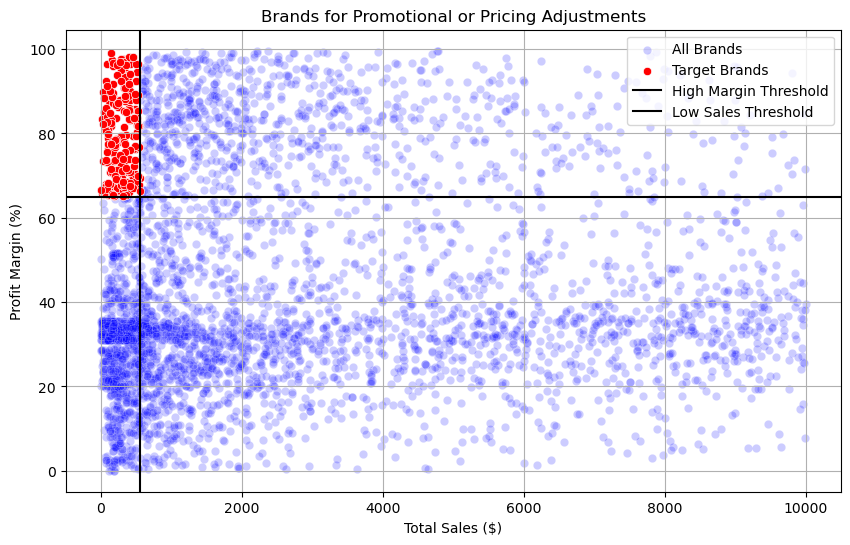

In [33]:
plt.figure(figsize=(10,6))
sns.scatterplot(data=brand_performance, x='TotalSalesDollars', y='ProfitMargin', color="blue", label="All Brands", alpha = 0.2)
sns.scatterplot(data=target_brands, x= 'TotalSalesDollars', y='ProfitMargin', color="red", label="Target Brands")

plt.axhline(high_margin_threshold, linestyle='-', color='black', label="High Margin Threshold")
plt.axvline(low_sales_threshold, linestyle='-', color='black', label="Low Sales Threshold")

plt.xlabel("Total Sales ($)")
plt.ylabel("Profit Margin (%)")
plt.title("Brands for Promotional or Pricing Adjustments")
plt.legend()
plt.grid(True)
plt.show()

Which vendor and brands demonstrate the highest sales performance?

In [36]:
def format_dollars (value):
    if value >= 1_000_000:
        return f"(value / 1_000_000:.2)M"
    elif value >= 1_000:
        return f"(value / 1_000:.2f)K"
    else:
        return str(value)

In [38]:
#Top Vendors and Brands by Sales Performance
top_vendors = df.groupby("VendorName") ["TotalSalesDollars"].sum().nlargest(10)
top_brands= df.groupby("Description") ["TotalSalesDollars"].sum().nlargest(10)
top_vendors

VendorName
DIAGEO NORTH AMERICA INC      67990099.42
MARTIGNETTI COMPANIES         39330359.36
PERNOD RICARD USA             32063196.19
JIM BEAM BRANDS COMPANY       31423020.46
BACARDI USA INC               24854817.14
CONSTELLATION BRANDS INC      24218745.65
E & J GALLO WINERY            18399899.46
BROWN-FORMAN CORP             18247230.65
ULTRA BEVERAGE COMPANY LLP    16502544.31
M S WALKER INC                14706458.51
Name: TotalSalesDollars, dtype: float64

In [39]:
top_brands

Description
Jack Daniels No 7 Black    7964746.76
Tito's Handmade Vodka      7399657.58
Grey Goose Vodka           7209608.06
Capt Morgan Spiced Rum     6356320.62
Absolut 80 Proof           6244752.03
Jameson Irish Whiskey      5715759.69
Ketel One Vodka            5070083.56
Baileys Irish Cream        4150122.07
Kahlua                     3604858.66
Tanqueray                  3456697.90
Name: TotalSalesDollars, dtype: float64

In [43]:
#for readability
target_brands.groupby('Description')['TotalSalesDollars'].sum().map(
    lambda value: f"{value / 1_000_000:.2f}M"
)

Description
12 Days of Pearls Gift Set      0.00M
4 Orange Vodka                  0.00M
A Bichot Clos Marechaudes       0.00M
A Bichot Merc Champs M          0.00M
Absolut Orient Apple Vodka      0.00M
                                ...  
Woodford Rsv Master Coll Pnt    0.00M
Zardetto Pros di Coneg Brut     0.00M
Zerran Tinto Montsant           0.00M
Zhenka Vodka 80 Proof           0.00M
Zorah Red                       0.00M
Name: TotalSalesDollars, Length: 198, dtype: object

In [45]:
target_brands['TotalSalesDollars'].tail(10)

7384    359.82
7385    272.79
7413    314.70
7448    167.88
7574    194.85
7589    489.95
7664    345.86
7678    139.91
7687    240.39
7697    417.81
Name: TotalSalesDollars, dtype: float64

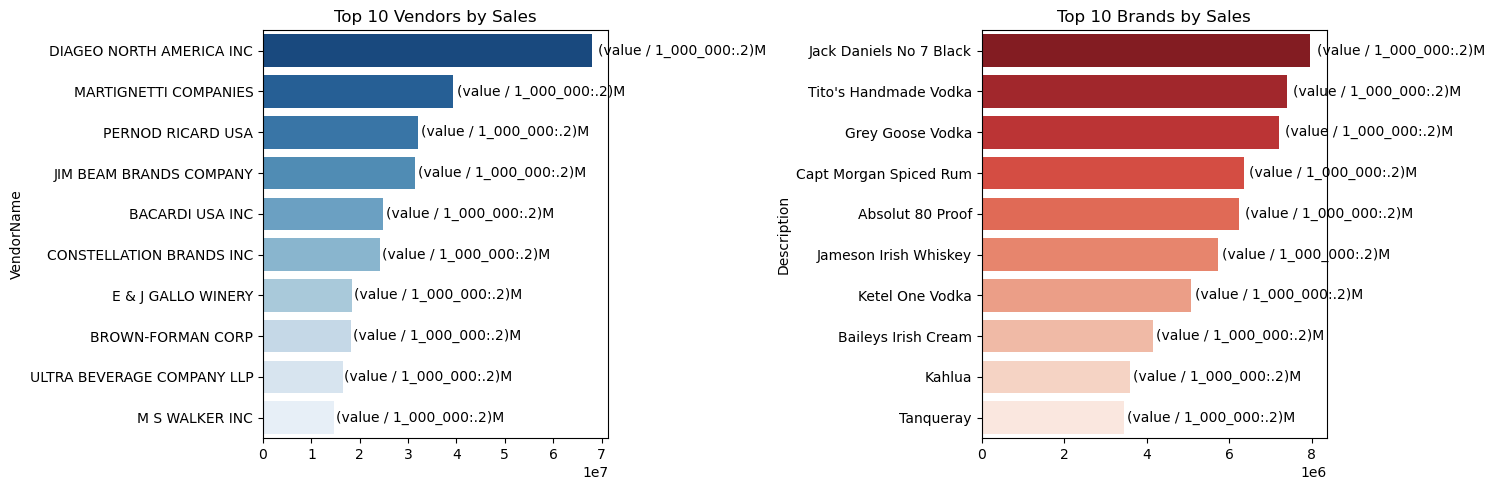

In [46]:

plt.figure(figsize=(15, 5))

#Plot for Top Vendors
plt.subplot(1, 2, 1)
ax1 =sns.barplot(y=top_vendors.index, x=top_vendors.values, palette="Blues_r") 
plt.title("Top 10 Vendors by Sales")

for bar in ax1.patches:
    ax1.text(bar.get_width() + (bar.get_width() * 0.02),
             bar.get_y() + bar.get_height() / 2,
             format_dollars(bar.get_width()), 
             ha='left', va='center', fontsize=10, color='black')

# Plot for Top Brands
plt.subplot(1, 2, 2)
ax2 =sns.barplot(y=top_brands.index.astype(str), x=top_brands.values, palette="Reds_r")
plt.title("Top 10 Brands by Sales")

for bar in ax2.patches:
    ax2.text(bar.get_width() + (bar.get_width() * 0.02),
             bar.get_y() + bar.get_height() / 2, 
             format_dollars(bar.get_width()),
             ha='left', va='center', fontsize=10, color='black')
plt.tight_layout()
plt.show()



Which Vendors contribute the most to Total Purchase Dollars?

In [56]:

vendor_performance = df.groupby('VendorName').agg({
'TotalPurchaseDollars': 'sum',
'GrossProfit': 'sum',
'TotalSalesDollars': 'sum'

}).reset_index()
vendor_performance.shape
vendor_performance ['PurchaseContribution%'] = vendor_performance ['TotalPurchaseDollars']/ vendor_performance ['TotalPurchaseDollars'].sum()*100
vendor_performance = round (vendor_performance.sort_values('PurchaseContribution%', ascending = False), 2)

In [57]:
#Display Top 10 Vendors

top_vendors = vendor_performance.head(10)
top_vendors ['TotalSalesDollars'] = top_vendors['TotalSalesDollars'].apply(format_dollars)
top_vendors ['TotalPurchaseDollars'] = top_vendors ['TotalPurchaseDollars'].apply(format_dollars)
top_vendors ['GrossProfit'] = top_vendors ['GrossProfit'].apply(format_dollars)
top_vendors

,VendorName,TotalPurchaseDollars,GrossProfit,TotalSalesDollars,PurchaseContribution%
25,DIAGEO NORTH AMERICA INC,(value / 1_000_000:.2)M,(value / 1_000_000:.2)M,(value / 1_000_000:.2)M,16.30
57,MARTIGNETTI COMPANIES,(value / 1_000_000:.2)M,(value / 1_000_000:.2)M,(value / 1_000_000:.2)M,8.30
68,PERNOD RICARD USA,(value / 1_000_000:.2)M,(value / 1_000_000:.2)M,(value / 1_000_000:.2)M,7.76
46,JIM BEAM BRANDS COMPANY,(value / 1_000_000:.2)M,(value / 1_000_000:.2)M,(value / 1_000_000:.2)M,7.64
6,BACARDI USA INC,(value / 1_000_000:.2)M,(value / 1_000_000:.2)M,(value / 1_000_000:.2)M,5.67
20,CONSTELLATION BRANDS INC,(value / 1_000_000:.2)M,(value / 1_000_000:.2)M,(value / 1_000_000:.2)M,4.97
11,BROWN-FORMAN CORP,(value / 1_000_000:.2)M,(value / 1_000_000:.2)M,(value / 1_000_000:.2)M,4.31
30,E & J GALLO WINERY,(value / 1_000_000:.2)M,(value / 1_000_000:.2)M,(value / 1_000_000:.2)M,3.93
106,ULTRA BEVERAGE COMPANY LLP,(value / 1_000_000:.2)M,(value / 1_000_000:.2)M,(value / 1_000_000:.2)M,3.63
53,M S WALKER INC,(value / 1_000_000:.2)M,(value / 1_000_000:.2)M,(value / 1_000_000:.2)M,3.18


In [58]:
top_vendors['PurchaseContribution%'].sum()

np.float64(65.69000000000001)

KeyError: 'Purchase_Contribution%'

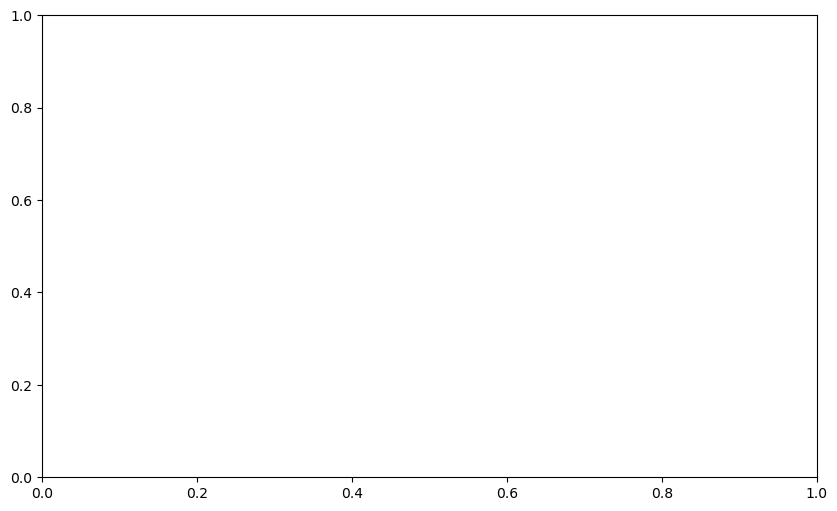

In [61]:
fig, ax1 = plt.subplots(figsize=(10, 6))

# Bar plot for Purchase Contribution %
sns.barplot(
    x=top_vendors['VendorName'],
    y=top_vendors['Purchase_Contribution%'],
    palette="mako",
    ax=ax1
)

# Add percentage values on bars
for i, value in enumerate(top_vendors['Purchase_Contribution%']):
    ax1.text(
        i,
        value + 1,
        f'{value:.2f}%',
        ha='center',
        fontsize=10,
        color='white'
    )

# Line plot for Cumulative Contribution %
ax2 = ax1.twinx()

ax2.plot(
    top_vendors['VendorName'],
    top_vendors['Cumulative_Contribution%'],
    color='red',
    marker='o',
    linestyle='dashed',
    label='Cumulative Contribution %'
)

ax1.set_xticklabels(
    top_vendors['VendorName'],
    rotation=90
)

ax1.set_ylabel('Purchase Contribution %')
ax2.set_ylabel('Cumulative Contribution %')
ax1.set_xlabel('Vendors')

ax1.set_title('Pareto Chart: Vendor Contribution to Total Purchases')

ax2.axhline(
    y=100,
    color='gray',
    linestyle='dashed',
    alpha=0.7
)

ax2.legend(loc='upper right')

plt.show()

How much of total procurement is dependent on top vendors?

In [66]:
print(
    f"Total Purchase Contribution of top 10 vendors is "
    f"{round(top_vendors['PurchaseContribution%'].sum(), 2)}%"
)

Total Purchase Contribution of top 10 vendors is 65.69%


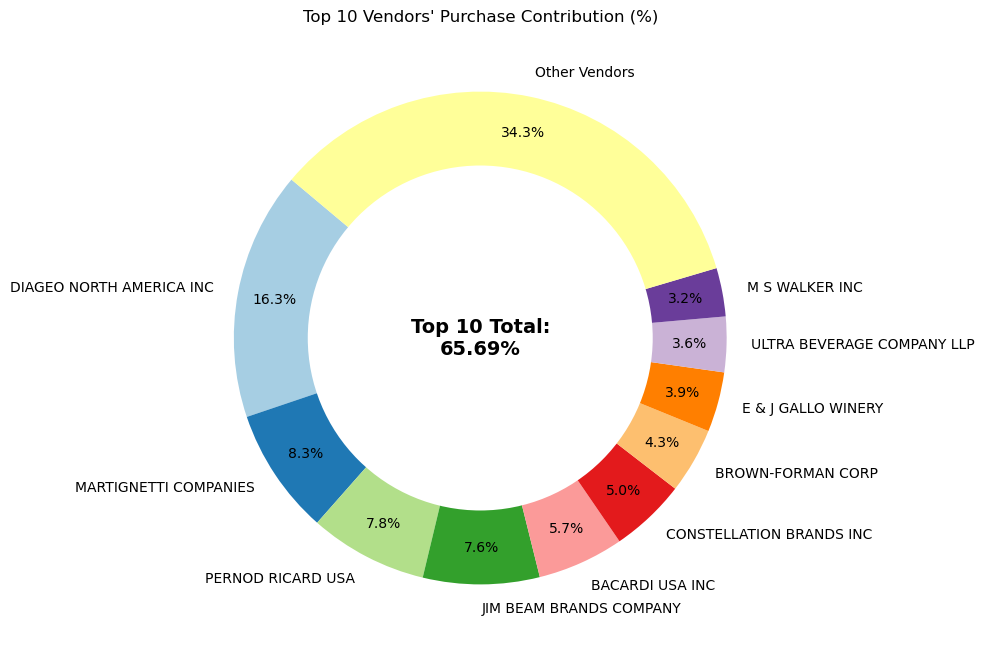

In [70]:

vendors = list(top_vendors['VendorName'].values)

purchase_contributions = list(
    top_vendors['PurchaseContribution%'].values
)

total_contribution = sum(purchase_contributions)
remaining_contribution = 100 - total_contribution

# Append "Other Vendors"
vendors.append("Other Vendors")
purchase_contributions.append(remaining_contribution)

# Donut Chart
fig, ax = plt.subplots(figsize=(8, 8))

wedges, texts, autotexts = ax.pie(
    purchase_contributions,
    labels=vendors,
    autopct='%1.1f%%',
    startangle=140,
    pctdistance=0.85,
    colors=plt.cm.Paired.colors
)

# White circle in center → Donut effect
centre_circle = plt.Circle(
    (0, 0),
    0.70,
    fc='white'
)

fig.gca().add_artist(centre_circle)

# Total Contribution in center
plt.text(
    0,
    0,
    f"Top 10 Total:\n{total_contribution:.2f}%",
    fontsize=14,
    fontweight='bold',
    ha='center',
    va='center'
)

plt.title("Top 10 Vendors' Purchase Contribution (%)")

plt.show()

Does purchasing in bulk reduce the unit price, and what is the optimal purchase volume for cost savings?

In [72]:
df['UnitPurchasePrice'] = df['TotalPurchaseDollars']/df['TotalPurchaseQuantity']

In [74]:
df["OrderSize"] = pd.qcut(df["TotalPurchaseQuantity"], q=3, labels=["Small","Medium","Large"])

In [75]:
df.groupby('OrderSize')[['UnitPurchasePrice']].mean()

,UnitPurchasePrice
OrderSize,
Small,39.068186
Medium,15.482067
Large,10.774898


 Which vendors have low inventory turnover,indicating excess stock and slow moving products?

In [77]:
df[df['StockTurnover']<1].groupby('VendorName')[['StockTurnover']].mean().sort_values('StockTurnover',ascending=True).head(10)

,StockTurnover
VendorName,
ALISA CARR BEVERAGES,0.615385
HIGHLAND WINE MERCHANTS LLC,0.708333
PARK STREET IMPORTS LLC,0.751306
Circa Wines,0.755676
Dunn Wine Brokers,0.766022
CENTEUR IMPORTS LLC,0.773953
SMOKY QUARTZ DISTILLERY LLC,0.783835
TAMWORTH DISTILLING,0.797078
THE IMPORTED GRAPE LLC,0.807569


How much capital is locked in unsold inventory per vendor and which vendors contribute the most to it?

In [79]:
df ["UnsoldInventoryValue"] = (df ["TotalPurchaseQuantity"]- df ["TotalSalesQuantity"]) * df ["PurchasePrice"]
print('Total Unsold Capital:', format_dollars (df ["UnsoldInventoryValue"].sum()))

Total Unsold Capital: (value / 1_000_000:.2)M


In [80]:
# Aggregate Capital Locked per Vendor
inventory_value_per_vendor = df.groupby("VendorName") ["UnsoldInventoryValue"].sum().reset_index()

#Sort Vendors with the Highest Locked Capital
inventory_value_per_vendor = inventory_value_per_vendor.sort_values(by="UnsoldInventoryValue", ascending=False)
inventory_value_per_vendor ['UnsoldInventoryValue'] = inventory_value_per_vendor ['UnsoldInventoryValue'].apply(format_dollars)
inventory_value_per_vendor.head(10)

,VendorName,UnsoldInventoryValue
25,DIAGEO NORTH AMERICA INC,(value / 1_000:.2f)K
46,JIM BEAM BRANDS COMPANY,(value / 1_000:.2f)K
68,PERNOD RICARD USA,(value / 1_000:.2f)K
116,WILLIAM GRANT & SONS INC,(value / 1_000:.2f)K
30,E & J GALLO WINERY,(value / 1_000:.2f)K
79,SAZERAC CO INC,(value / 1_000:.2f)K
11,BROWN-FORMAN CORP,(value / 1_000:.2f)K
20,CONSTELLATION BRANDS INC,(value / 1_000:.2f)K
61,MOET HENNESSY USA INC,(value / 1_000:.2f)K
77,REMY COINTREAU USA INC,(value / 1_000:.2f)K


What is the 95% confidence intervals for profit margins of top performing and low performing vendors?

In [83]:
top_threshold = df ["TotalSalesDollars"].quantile(0.75)

low_threshold = df ["TotalSalesDollars"].quantile(0.25)

In [87]:

top_vendors = df [df ["TotalSalesDollars"] >= top_threshold] ["ProfitMargin"].dropna()

low_vendors = df [df ["TotalSalesDollars"] <= low_threshold] ["ProfitMargin"].dropna()


In [88]:
top_vendors

0        25.297693
1        21.062810
2        24.675786
3        27.139908
4        28.412764
           ...    
3681     85.782102
4751     93.085860
4920     95.012530
5050     94.271857
8564    100.000000
Name: ProfitMargin, Length: 2142, dtype: float64

In [89]:
def confidence_interval(data, confidence=0.95):
    mean_val = np.mean(data)
    std_err = np.std(data, ddof=1) / np.sqrt(len(data)) # Standard error
    t_critical = stats.t.ppf ((1+ confidence) / 2, df=len(data) -1)
    margin_of_error = t_critical * std_err
    return mean_val, mean_val - margin_of_error, mean_val + margin_of_error

Top Vendors 95% CI: (30.77, 31.65), Mean: 31.21
Low Vendors 95% CI: (40.49, 42.63), Mean: 41.56


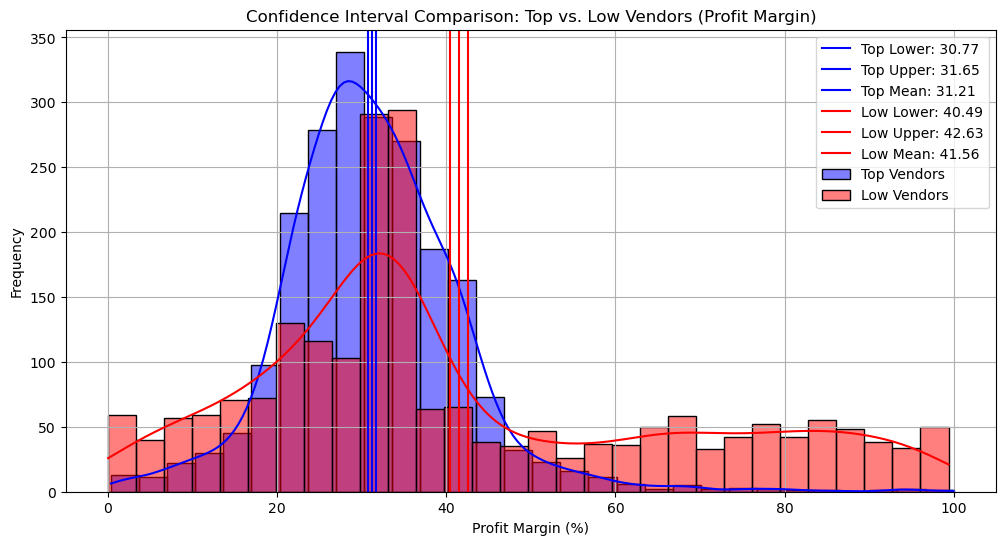

In [92]:
top_mean, top_lower, top_upper = confidence_interval(top_vendors)
low_mean, low_lower, low_upper = confidence_interval(low_vendors)

print(f"Top Vendors 95% CI: ({top_lower:.2f}, {top_upper:.2f}), Mean: {top_mean:.2f}") 
print(f"Low Vendors 95% CI: ({low_lower:.2f}, {low_upper:.2f}), Mean: {low_mean:.2f}")
plt.figure(figsize=(12, 6))

#Top Vendors Plot
sns.histplot(top_vendors, kde=True, color="blue", bins=30, alpha=0.5, label="Top Vendors")
plt.axvline(top_lower, color="blue", linestyle="-", label=f"Top Lower: {top_lower:.2f}")
plt.axvline(top_upper, color="blue", linestyle="-", label=f"Top Upper: {top_upper:.2f}")
plt.axvline(top_mean, color="blue", linestyle="-", label=f"Top Mean: {top_mean:.2f}")

#Low Vendors Plot
sns.histplot(low_vendors, kde =True, color="red", bins=30, alpha=0.5, label="Low Vendors")
plt.axvline(low_lower, color="red", linestyle="-", label=f"Low Lower: {low_lower:.2f}")
plt.axvline(low_upper, color="red", linestyle="-", label=f"Low Upper: {low_upper:.2f}")
plt.axvline(low_mean, color="red", linestyle="-", label=f"Low Mean: {low_mean:.2f}")

#Finalize Plot
plt.title("Confidence Interval Comparison: Top vs. Low Vendors (Profit Margin)")
plt.xlabel("Profit Margin (%)")
plt.ylabel("Frequency")
plt.legend()
plt.grid(True)
plt.show()

In [93]:
import pandas as pd
import logging
import sqlite3

from ingestion_db import ingest_db


# Logging - to record the events
logging.basicConfig(
    filename="logs/get_vendor_summary.log",
    level=logging.DEBUG,
    format="%(asctime)s - %(levelname)s - %(message)s",
    filemode="a"
)


def create_vendor_summary(conn):
    """
    Merge different tables to get the overall vendor summary
    and create a consolidated dataset.
    """

    vendor_sales_summary = pd.read_sql_query("""

    WITH FreightSummary AS (
        SELECT
            VendorNumber,
            SUM(Freight) AS FreightCost
        FROM vendor_invoice
        GROUP BY VendorNumber
    ),

    PurchaseSummary AS (
        SELECT
            p.VendorNumber,
            p.VendorName,
            p.Brand,
            p.Description,
            p.PurchasePrice,
            pp.Price AS ActualPrice,
            pp.Volume,
            SUM(p.Quantity) AS TotalPurchaseQuantity,
            SUM(p.Dollars) AS TotalPurchaseDollars
        FROM purchases p
        JOIN purchase_prices pp
            ON p.Brand = pp.Brand
        GROUP BY
            p.VendorNumber,
            p.VendorName,
            p.Brand,
            p.Description,
            p.PurchasePrice,
            pp.Price,
            pp.Volume
    ),

    SalesSummary AS (
        SELECT
            VendorNo,
            Brand,
            SUM(SalesQuantity) AS TotalSalesQuantity,
            SUM(SalesDollars) AS TotalSalesDollars,
            SUM(SalesPrice) AS TotalSalesPrice,
            SUM(ExciseTax) AS TotalExciseTax
        FROM sales
        GROUP BY VendorNo, Brand
    )

    SELECT
        ps.VendorNumber,
        ps.VendorName,
        ps.Brand,
        ps.Description,
        ps.PurchasePrice,
        ps.ActualPrice,
        ps.Volume,
        ps.TotalPurchaseQuantity,
        ps.TotalPurchaseDollars,
        ss.TotalSalesQuantity,
        ss.TotalSalesDollars,
        ss.TotalSalesPrice,
        ss.TotalExciseTax,
        fs.FreightCost

    FROM PurchaseSummary ps

    LEFT JOIN SalesSummary ss
        ON ps.VendorNumber = ss.VendorNo
        AND ps.Brand = ss.Brand

    LEFT JOIN FreightSummary fs
        ON ps.VendorNumber = fs.VendorNumber

    ORDER BY ps.TotalPurchaseDollars DESC

    """, conn)

    return vendor_sales_summary


def clean_data(df):

    # Changing datatype to float
    df['Volume'] = df['Volume'].astype('float64')

    # Filling missing values with 0
    df.fillna(0, inplace=True)

    # Removing extra spaces from categorical columns
    df['VendorName'] = df['VendorName'].str.strip()
    df['Description'] = df['Description'].str.strip()

    # Creating new columns for better analysis

    df['GrossProfit'] = (
        df['TotalSalesDollars']
        - df['TotalPurchaseDollars']
    )

    df['ProfitMargin'] = (
        df['GrossProfit']
        / df['TotalSalesDollars']
    ) * 100

    df['StockTurnover'] = (
        df['TotalSalesQuantity']
        / df['TotalPurchaseQuantity']
    )

    df['SalestoPurchaseRatio'] = (
        df['TotalSalesDollars']
        / df['TotalPurchaseDollars']
    )

    return df


if __name__ == "__main__":

    # Creating database connection
    conn = sqlite3.connect('inventory.db')

    logging.info('Creating Vendor Summary Table.....')

    summary_df = create_vendor_summary(conn)
    logging.info(summary_df.head())

    logging.info('Cleaning Data.....')

    clean_df = clean_data(summary_df)
    logging.info(clean_df.head())

    logging.info('Ingesting data.....')

    ingest_db(clean_df, 'vendor_sales_summary', conn)

    logging.info('Completed')

    conn.close()